# Football match outcome probabilities: an LSTM against the betting market

Pre-match probabilities for **home win, draw and away win** in 11 European leagues
(2008–2016), learned from each team's recent results and benchmarked against the
probabilities implied by bookmaker odds.

1. Data
2. The market as a benchmark
3. Leakage-free features
4. Models
5. Test results: model vs. market
6. Value-betting backtest
7. Export for the API

All reusable code lives in [`src/football`](../src/football); this notebook tells the story.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from football import CLASSES, backtest, data, evaluation, features, models

FIGURES = ROOT / "reports" / "figures"
ARTIFACTS = ROOT / "artifacts"
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

## 1. Data

[European Soccer Database](https://www.kaggle.com/datasets/hugomathien/soccer) (Kaggle):
every league match of 11 European top divisions from 2008/09 to 2015/16, with final
scores and pre-match odds from several bookmakers. It is downloaded with `kagglehub`
on the first run.

In [2]:
matches = data.load_matches()
print(f"{len(matches):,} matches | {matches.league.nunique()} leagues | "
      f"{matches.season.nunique()} seasons ({matches.date.min():%b %Y} - {matches.date.max():%b %Y})")

(matches.result.value_counts(normalize=True).sort_index()
 .rename(index=dict(enumerate(CLASSES))).rename("share of matches").to_frame().T)

25,979 matches | 11 leagues | 8 seasons (Jul 2008 - May 2016)


result,home,draw,away
share of matches,0.4587,0.2539,0.2874


Home advantage is clear: the home side wins 46% of matches. A model that always
predicts "home win" is already 46% accurate, which is why **accuracy is a poor yardstick**
here and the project focuses on the quality of the probabilities.

## 2. The market as a benchmark

Decimal odds $o_k$ imply probabilities $1/o_k$ that add up to more than 1: the excess
(the *overround*) is the bookmaker's margin. Normalizing removes it:

$$\pi_k = \frac{1/o_k}{\sum_{j} 1/o_j}, \qquad k \in \{\text{home}, \text{draw}, \text{away}\}$$

The market aggregates far more information than past results (injuries, line-ups,
news, betting flows), so it is a demanding benchmark. Two books are used: **Bet365**, a
large retail bookmaker, and **Pinnacle**, known for low margins and sharp prices.

In [3]:
market = {}
for book, name in data.BOOKMAKERS.items():
    o = data.odds(matches, book)
    has = ~np.isnan(o).any(axis=1)
    _, overround = data.implied_probabilities(o[has])
    market[name] = {"matches with odds": has.mean(), "average margin": overround.mean() - 1}
pd.DataFrame(market).T

,matches with odds,average margin
Bet365,0.8696,0.0615
Pinnacle,0.4299,0.0238


## 3. Leakage-free features

For every match, each team is described by its **last N matches before kick-off**:
goals for, goals against, goal difference, points and whether it played at home.
Matches are processed in chronological order and a team's history is updated only
*after* the sample for the current match has been built, so no result can leak into
its own prediction (see `tests/test_features.py`).

The split is also chronological, by season:

| Set | Seasons | Use |
|---|---|---|
| Train | 2008/09 – 2013/14 | fit the models |
| Validation | 2014/15 | early stopping, window length, betting threshold |
| Test | 2015/16 | final evaluation, used once |

Feature scaling is fitted on the training seasons only.

In [4]:
teams = features.index_map(np.r_[matches.home_team, matches.away_team])
leagues = features.index_map(matches.league_id)


def make_dataset(window):
    s = features.build_sequences(matches, window)
    s["masks"] = features.split_masks(s["date"])
    train = s["masks"]["train"]
    s["scaler"] = features.SequenceScaler().fit(s["home_seq"][train], s["away_seq"][train])
    return s


def lstm_inputs(s, mask):
    return [s["scaler"].transform(s["home_seq"][mask]),
            s["scaler"].transform(s["away_seq"][mask]),
            np.array([teams[t] for t in s["home_team"][mask]]),
            np.array([teams[t] for t in s["away_team"][mask]]),
            np.array([leagues[l] for l in s["league"][mask]])]


datasets = {w: make_dataset(w) for w in (5, 10)}
pd.DataFrame({f"window = {w}": {k: int(m.sum()) for k, m in s["masks"].items()}
              for w, s in datasets.items()})

,window = 5,window = 10
train,18429,17543
val,3270,3212
test,3262,3199


## 4. Models

* **LSTM**: a shared LSTM encodes the recent form of both teams; team and league
  embeddings capture persistent strength and league effects; a small dense head outputs
  the three probabilities. Trained on log-loss with early stopping on the validation season.
* **LSTM, class-weighted**: the same network with balanced class weights, as in the
  original version of this project. Weights push the model to predict more draws, which
  raises macro-F1 but distorts the probabilities.
* **Baselines**: historical base rates, a multinomial logistic regression and a small
  feed-forward network (MLP), both on window averages of the same features.

First, the window length is chosen on the validation season.

In [5]:
lstms, val_scores = {}, {}
for w, s in datasets.items():
    tr, va = s["masks"]["train"], s["masks"]["val"]
    models.set_seed()
    lstms[w] = models.build_lstm(len(teams), len(leagues), w)
    models.fit(lstms[w], lstm_inputs(s, tr), s["y"][tr], lstm_inputs(s, va), s["y"][va])
    val_scores[f"window = {w}"] = evaluation.scores(
        s["y"][va], lstms[w].predict(lstm_inputs(s, va), verbose=0))

WINDOW = min(datasets, key=lambda w: val_scores[f"window = {w}"]["log_loss"])
print(f"Selected window: last {WINDOW} matches")
pd.DataFrame(val_scores).T

Selected window: last 5 matches


,log_loss,brier,accuracy,macro_f1
window = 5,1.0007,0.5978,0.5067,0.3693
window = 10,1.0014,0.5983,0.5118,0.3703


In [6]:
s = datasets[WINDOW]
tr, va, te = (s["masks"][k] for k in ("train", "val", "test"))
y = s["y"]
lstm = lstms[WINDOW]

# Same architecture with balanced class weights (original project setup)
weights = compute_class_weight("balanced", classes=np.arange(3), y=y[tr])
models.set_seed()
lstm_weighted = models.build_lstm(len(teams), len(leagues), WINDOW)
models.fit(lstm_weighted, lstm_inputs(s, tr), y[tr], lstm_inputs(s, va), y[va],
           class_weight=dict(enumerate(weights)))

# Tabular baselines on window averages
Z = features.summary_features(s["home_seq"], s["away_seq"])
z_scaler = StandardScaler().fit(Z[tr])
models.set_seed()
mlp = models.build_mlp(Z.shape[1])
models.fit(mlp, z_scaler.transform(Z[tr]), y[tr], z_scaler.transform(Z[va]), y[va])
logit = LogisticRegression(max_iter=1000).fit(z_scaler.transform(Z[tr]), y[tr])
base_rates = np.bincount(y[tr], minlength=3) / tr.sum()

print(f"LSTM: {lstm.count_params():,} parameters")

LSTM: 18,335 parameters


## 5. Test results: model vs. market

All models are compared on the same test matches: those where both bookmakers
published odds. **Log-loss** and the **Brier score** are proper scoring rules (lower is
better): they reward probabilities that are both sharp and well calibrated. Accuracy and
macro-F1 only look at the most likely outcome and are shown for reference.

In [7]:
rows = matches.iloc[s["index"]]
book_odds = {name: data.odds(rows, book) for book, name in data.BOOKMAKERS.items()}
has_odds = ~np.isnan(np.hstack(list(book_odds.values()))).any(axis=1)


def forecasts(mask):
    """Probabilities from every model for the matches in `mask`."""
    z = z_scaler.transform(Z[mask])
    out = {"Base rates": np.tile(base_rates, (mask.sum(), 1)),
           "Logistic regression": logit.predict_proba(z),
           "MLP (window averages)": mlp.predict(z, verbose=0),
           "LSTM, class-weighted": lstm_weighted.predict(lstm_inputs(s, mask), verbose=0),
           "LSTM": lstm.predict(lstm_inputs(s, mask), verbose=0)}
    for name, o in book_odds.items():
        out[f"{name} (implied)"] = data.implied_probabilities(o[mask])[0]
    return out


test = te & has_odds
test_fc = forecasts(test)
results = evaluation.score_table(y[test], test_fc)
print(f"Test season 2015/16: {test.sum():,} matches")
results

Test season 2015/16: 2,843 matches


,log_loss,brier,accuracy,macro_f1
Base rates,1.0699,0.6470,0.4457,0.2055
Logistic regression,1.0319,0.6199,0.4854,0.3361
MLP (window averages),1.0292,0.6181,0.4865,0.3357
"LSTM, class-weighted",1.0361,0.6196,0.4632,0.4375
LSTM,1.0039,0.6002,0.5065,0.3688
Bet365 (implied),0.9775,0.5823,0.5220,0.3805
Pinnacle (implied),0.9777,0.5825,0.5216,0.3804


In [8]:
ll = results["log_loss"]
gap = (ll["Base rates"] - ll["LSTM"]) / (ll["Base rates"] - ll["Bet365 (implied)"])
print(f"The LSTM closes {gap:.0%} of the log-loss gap between base rates and Bet365.\n")

comparisons = {"LSTM vs MLP": ("LSTM", "MLP (window averages)"),
               "LSTM vs Bet365": ("LSTM", "Bet365 (implied)"),
               "LSTM vs class-weighted LSTM": ("LSTM", "LSTM, class-weighted")}
pd.DataFrame({name: evaluation.paired_bootstrap(y[test], test_fc[a], test_fc[b])
              for name, (a, b) in comparisons.items()}).T.rename(
    columns={"diff": "log-loss difference", "low": "95% CI low", "high": "95% CI high"})

The LSTM closes 71% of the log-loss gap between base rates and Bet365.



,log-loss difference,95% CI low,95% CI high
LSTM vs MLP,-0.0253,-0.0346,-0.0161
LSTM vs Bet365,0.0265,0.0178,0.0347
LSTM vs class-weighted LSTM,-0.0322,-0.0423,-0.0220


Negative differences favour the LSTM. The intervals come from a paired bootstrap over
test matches (it ignores the correlation between matches of the same round, so they are
slightly optimistic).

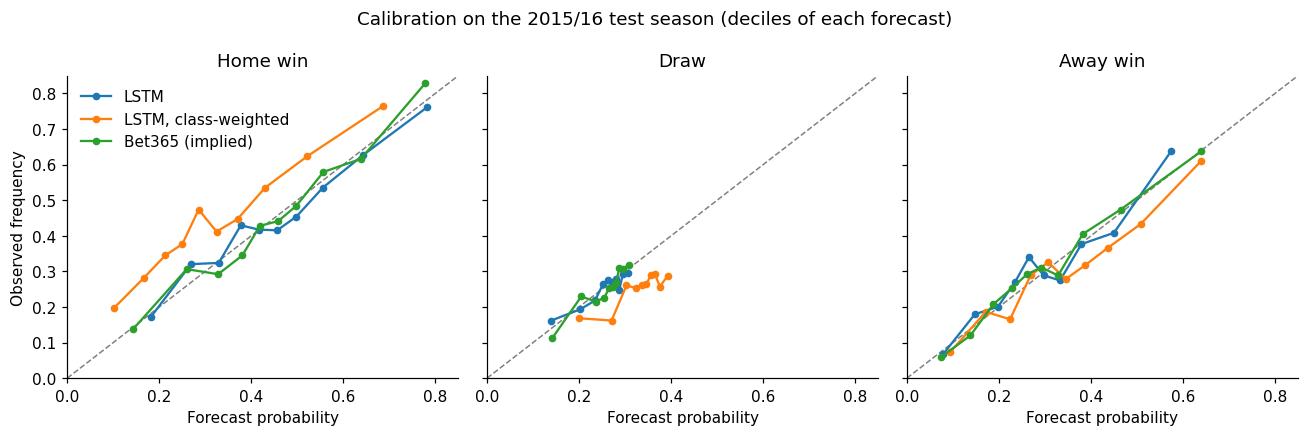

In [9]:
TITLES = ("Home win", "Draw", "Away win")
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for k, ax in enumerate(axes):
    ax.plot([0, 0.85], [0, 0.85], color="grey", lw=1, ls="--")
    for name in ("LSTM", "LSTM, class-weighted", "Bet365 (implied)"):
        c = evaluation.calibration_curve(y[test], test_fc[name], k)
        ax.plot(c["forecast"], c["observed"], marker="o", ms=4, label=name)
    ax.set(title=TITLES[k], xlabel="Forecast probability", xlim=(0, 0.85), ylim=(0, 0.85))
axes[0].set_ylabel("Observed frequency")
axes[0].legend(frameon=False)
fig.suptitle("Calibration on the 2015/16 test season (deciles of each forecast)")
fig.tight_layout()
fig.savefig(FIGURES / "calibration.png", dpi=150, bbox_inches="tight")

Points on the diagonal mean "when the model says 30%, it happens 30% of the time".
The LSTM and the market are both close to it. Class weights move probability from home
wins to draws: the weighted model systematically **understates home wins** (curve above
the diagonal) and **overstates draws** (curve below it), which is exactly what log-loss
penalizes.

## 6. Value-betting backtest

If the model knew something the market did not, betting where it sees value should make
money. Rule: in each match, bet 1 unit at **Bet365 odds** on the outcome with the highest
expected value $p_k\,o_k - 1$, but only if it exceeds a minimum edge. The minimum edge is
chosen on the validation season and then applied once to the test season.

In [10]:
EDGES = [0.0, 0.02, 0.05, 0.10, 0.20]
masks = {"validation": va & has_odds, "test": test}
p_lstm = {"validation": lstm.predict(lstm_inputs(s, masks["validation"]), verbose=0),
          "test": test_fc["LSTM"]}

grid = {}
for split, mask in masks.items():
    for edge in EDGES:
        bets = backtest.value_bets(p_lstm[split], book_odds["Bet365"][mask], edge)
        grid[(split, edge)] = backtest.summary(backtest.settle(bets, y[mask]))
grid = pd.DataFrame(grid).T.rename_axis(["season", "min edge"])
grid["bets"] = grid["bets"].astype(int)

EDGE = grid.loc["validation", "roi"].idxmax()
print(f"Minimum edge chosen on validation: {EDGE:.0%}")
grid

Minimum edge chosen on validation: 0%


bets  hit_rate     roi  roi_low  roi_high
season     min edge                                           
validation 0.00      2503    0.3080 -0.0710  -0.1379   -0.0051
           0.02      2295    0.2972 -0.0878  -0.1542   -0.0153
           0.05      1999    0.2781 -0.1014  -0.1802   -0.0254
           0.10      1610    0.2509 -0.1390  -0.2245   -0.0504
           0.20      1060    0.2047 -0.1812  -0.2937   -0.0639
test       0.00      2542    0.2954 -0.0545  -0.1275    0.0171
           0.02      2364    0.2902 -0.0451  -0.1206    0.0354
           0.05      2098    0.2831 -0.0416  -0.1251    0.0443
           0.10      1727    0.2675 -0.0320  -0.1254    0.0626
           0.20      1168    0.2329 -0.0321  -0.1552    0.0960

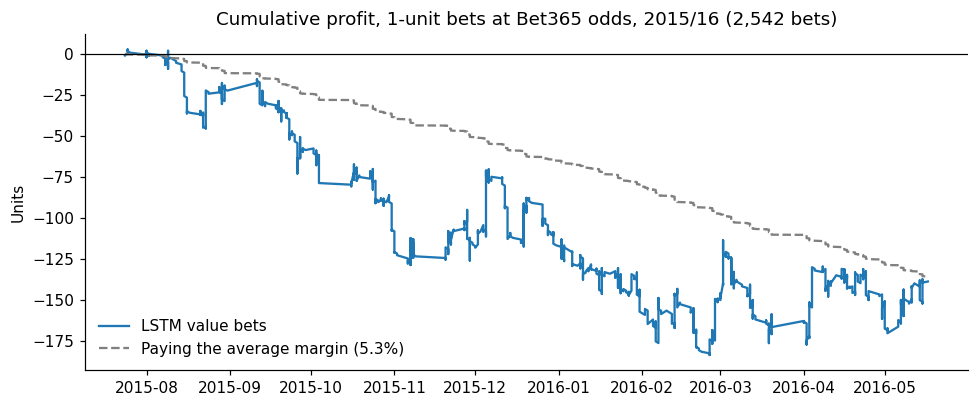

In [11]:
bets = backtest.value_bets(p_lstm["test"], book_odds["Bet365"][test], EDGE)
placed = backtest.settle(bets, y[test])
dates = pd.to_datetime(s["date"][test][placed.index])
margin = data.implied_probabilities(book_odds["Bet365"][test])[1].mean() - 1

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(dates, placed["profit"].cumsum().to_numpy(), label="LSTM value bets")
ax.plot(dates, -margin * np.arange(1, len(placed) + 1), ls="--", color="grey",
        label=f"Paying the average margin ({margin:.1%})")
ax.axhline(0, color="black", lw=0.8)
ax.set(title=f"Cumulative profit, 1-unit bets at Bet365 odds, 2015/16 ({len(placed):,} bets)",
       ylabel="Units")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "backtest.png", dpi=150, bbox_inches="tight")

## 7. Export for the API

The selected LSTM and its preprocessing (window length, scaling and id mappings) are
saved to `artifacts/`; `api/app.py` serves them with FastAPI. An example request is
written from the first test match.

In [12]:
ARTIFACTS.mkdir(exist_ok=True)
lstm.save(ARTIFACTS / "model.keras")
team_names = dict(zip(matches.home_team, matches.home_name))
preprocessing = {
    "window": int(WINDOW),
    "features": list(features.FEATURES),
    "mean": s["scaler"].mean_.tolist(),
    "std": s["scaler"].std_.tolist(),
    "teams": {str(k): v for k, v in teams.items()},
    "team_names": {str(k): team_names.get(k, str(k)) for k in teams},
    "leagues": {str(k): v for k, v in leagues.items()},
}
(ARTIFACTS / "preprocessing.json").write_text(json.dumps(preprocessing, indent=1), encoding="utf-8")

i = int(np.flatnonzero(test)[0])


def past_matches(seq):
    return [{"goals_for": int(r[0]), "goals_against": int(r[1]), "was_home": bool(r[4])}
            for r in seq]


example = {"home_team_id": int(s["home_team"][i]), "away_team_id": int(s["away_team"][i]),
           "league_id": int(s["league"][i]),
           "home_last_matches": past_matches(s["home_seq"][i]),
           "away_last_matches": past_matches(s["away_seq"][i])}
(ROOT / "api" / "example_request.json").write_text(json.dumps(example, indent=2), encoding="utf-8")

r = rows.iloc[i]
probs = lstm.predict(lstm_inputs(s, np.arange(len(y)) == i), verbose=0)[0]
implied = data.implied_probabilities(book_odds["Bet365"][[i]])[0][0]
print(f"{r.home_name} vs {r.away_name}, {r.date:%d %b %Y} (final score {r.home_goals}-{r.away_goals})")
print("LSTM:   ", {c: round(float(p), 3) for c, p in zip(CLASSES, probs)})
print("Bet365: ", {c: round(float(p), 3) for c, p in zip(CLASSES, implied)})

Sint-Truidense VV vs Club Brugge KV, 24 Jul 2015 (final score 2-1)
LSTM:    {'home': 0.201, 'draw': 0.269, 'away': 0.53}
Bet365:  {'home': 0.216, 'draw': 0.234, 'away': 0.55}


## Conclusions

* **Recent form carries real signal.** On the 2015/16 test season the LSTM reaches a
  log-loss of **1.004**, against 1.029 for the MLP on window averages and 1.070 for base
  rates. The gain over the MLP is clearly significant (95% CI of the difference: −0.035 to
  −0.016), so modelling the *sequence* of results adds information.
* **The market is still better.** Bet365's implied probabilities score **0.977**. The LSTM
  closes **71% of the gap** between knowing nothing and the bookmaker, but the remaining
  difference (0.026, CI 0.018 to 0.035) is what past scores cannot see: line-ups,
  injuries, transfers, news.
* **Choose the loss for the job.** Balanced class weights give the best macro-F1 (0.44)
  but the worst log-loss of all the neural models and visibly miscalibrated
  probabilities. For pricing, calibration matters more than classification metrics.
* **No exploitable edge.** Betting on the model's "value" at Bet365 odds returns
  **−5.5%** over 2,542 bets (95% CI −12.8% to +1.7%), close to the 5.3% average margin:
  the apparent edges are mostly noise, consistent with an efficient market.

**Limitations.** A single test season; the dataset does not say whether odds are opening
or closing prices; promoted teams without training history get untrained embeddings; the
bootstrap treats matches as independent.

**Next steps.** Feed the market probabilities into the model and test whether it adds
information *beyond* the market (for example, a logistic blend fitted on validation);
richer features such as Elo ratings or expected goals; rolling-origin evaluation over
several seasons.
